<a href="https://colab.research.google.com/github/Siddhant-Gulecha/Siddhant_Gulecha_23BDS0253/blob/main/EDA_Phase_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA Project - Phase 2
Statistical Analysis (1D, 2D, 3D) and Clustering (K-Means, Hierarchical)


## 1. Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage
from mpl_toolkits.mplot3d import Axes3D

sns.set_theme(style="whitegrid")

url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/SuicideChina.csv'
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv('SuicideChina.csv')

if 'rownames' in df.columns:
    df = df.drop(columns=['rownames'])
df = df.drop_duplicates()

df['Urban'] = df['Urban'].replace('unknown', 'Unknown')
df['Education'] = df['Education'].replace('unknown', 'Unknown')
df['Occupation'] = df['Occupation'].replace('others/unknown', 'Unknown')
df['method'] = df['method'].replace('unspecified', 'Unknown')

df['Age_Group'] = pd.cut(df['Age'], bins=[0, 18, 35, 60, 120], labels=['<18', '18-35', '36-59', '60+'], right=False)
df['Outcome'] = np.where(df['Died'] == 'yes', 'Fatal', 'Non-Fatal')

print("Shape:", df.shape)
df.head()


Shape: (2571, 13)


,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method,Age_Group,Outcome
0,1,yes,no,no,2010,12,female,39,Secondary,household,Other poison,36-59,Non-Fatal
1,2,no,yes,no,2009,3,male,83,primary,farming,Hanging,60+,Fatal
2,3,no,yes,no,2010,2,male,60,primary,farming,Hanging,60+,Fatal
3,4,no,yes,no,2011,1,male,73,primary,farming,Hanging,60+,Fatal
4,5,yes,no,no,2009,8,male,51,Secondary,farming,Pesticide,36-59,Non-Fatal


## 2. 1D Statistical Analysis

In [ ]:
age = df['Age']

stats_1d = pd.Series({
    'Count': age.count(),
    'Mean': age.mean(),
    'Median': age.median(),
    'Mode': age.mode()[0],
    'Variance': age.var(),
    'Std Dev': age.std(),
    'Min': age.min(),
    'Max': age.max(),
    'Range': age.max() - age.min(),
    'IQR': age.quantile(0.75) - age.quantile(0.25),
    'Skewness': stats.skew(age),
    'Kurtosis': stats.kurtosis(age)
})

print("1D Numerical Statistics for Age:")
print(stats_1d.round(2))


1D Numerical Statistics for Age:
Count       2571.00
Mean          52.63
Median        53.00
Mode          40.00
Variance     391.40
Std Dev       19.78
Min           12.00
Max          100.00
Range         88.00
IQR           32.00
Skewness       0.01
Kurtosis      -1.00
dtype: float64


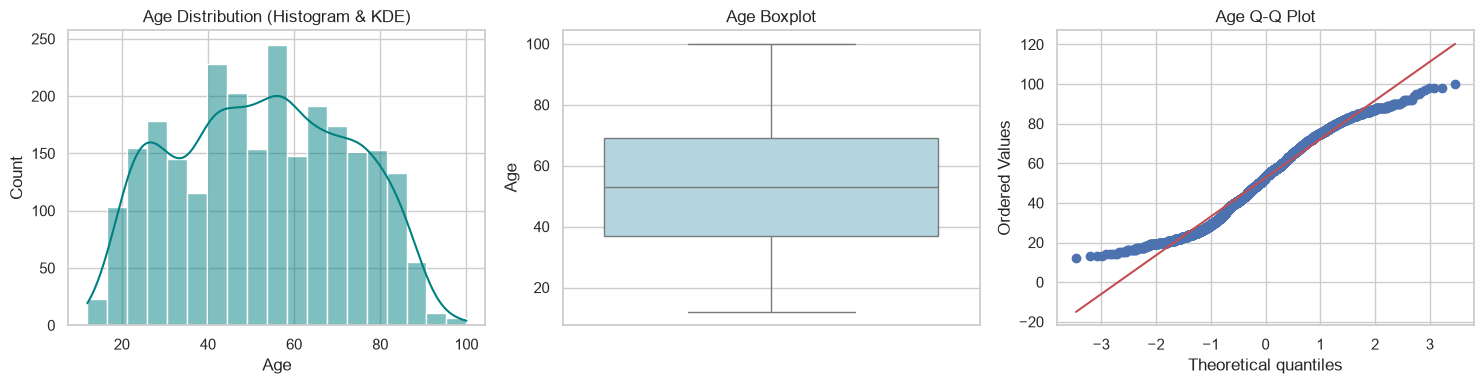

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['Age'], kde=True, color='teal', ax=axes[0])
axes[0].set_title('Age Distribution (Histogram & KDE)')

sns.boxplot(y=df['Age'], color='lightblue', ax=axes[1])
axes[1].set_title('Age Boxplot')

stats.probplot(df['Age'], dist="norm", plot=axes[2])
axes[2].set_title('Age Q-Q Plot')

plt.tight_layout()
plt.show()


In [ ]:
for col in ['Sex', 'Outcome', 'Urban', 'method']:
    cnt = df[col].value_counts()
    pct = df[col].value_counts(normalize=True) * 100
    tab = pd.DataFrame({'Count': cnt, 'Percentage (%)': pct.round(2)})
    print(f"--- Frequencies for {col} ---")
    print(tab)
    print()


--- Frequencies for Sex ---
        Count  Percentage (%)
Sex                          
female   1328           51.65
male     1243           48.35

--- Frequencies for Outcome ---
           Count  Percentage (%)
Outcome                         
Non-Fatal   1315           51.15
Fatal       1256           48.85

--- Frequencies for Urban ---
         Count  Percentage (%)
Urban                         
no        2213           86.08
yes        277           10.77
Unknown     81            3.15

--- Frequencies for method ---
               Count  Percentage (%)
method                              
Pesticide       1768           68.77
Hanging          431           16.76
Other poison     146            5.68
Poison unspec    107            4.16
Unknown           48            1.87
Cutting           29            1.13
Drowning          26            1.01
Jumping           15            0.58
Others             1            0.04



## 3. 2D Statistical Analysis

In [ ]:
# Categorical vs Categorical: Chi-square test (Sex vs Outcome)
ct_sex = pd.crosstab(df['Sex'], df['Outcome'])
chi2, p, dof, _ = stats.chi2_contingency(ct_sex)
n = ct_sex.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct_sex.shape) - 1)))

print("Contingency Table (Sex vs Outcome):")
print(ct_sex)
print(f"Chi-Square: {chi2:.4f}, p-value: {p:.4e}, DoF: {dof}, Cramer's V: {cramers_v:.4f}\n")

# Chi-square test (Method vs Outcome)
ct_method = pd.crosstab(df['method'], df['Outcome'])
chi2_m, p_m, dof_m, _ = stats.chi2_contingency(ct_method)
print("Chi-Square Test (Method vs Outcome):")
print(f"Chi-Square: {chi2_m:.4f}, p-value: {p_m:.4e}, DoF: {dof_m}")


Contingency Table (Sex vs Outcome):
Outcome  Fatal  Non-Fatal
Sex                      
female     587        741
male       669        574
Chi-Square: 23.3942, p-value: 1.3197e-06, DoF: 1, Cramer's V: 0.0954

Chi-Square Test (Method vs Outcome):
Chi-Square: 675.2192, p-value: 1.5452e-140, DoF: 8


In [ ]:
# Categorical vs Numerical: t-test and ANOVA
male_age = df[df['Sex'] == 'male']['Age']
female_age = df[df['Sex'] == 'female']['Age']
t_stat, t_pval = stats.ttest_ind(male_age, female_age)
print(f"t-test for Age by Sex: t = {t_stat:.4f}, p-value = {t_pval:.4e}")

fatal_age = df[df['Outcome'] == 'Fatal']['Age']
nonfatal_age = df[df['Outcome'] == 'Non-Fatal']['Age']
t_stat_o, t_pval_o = stats.ttest_ind(fatal_age, nonfatal_age)
print(f"t-test for Age by Outcome: t = {t_stat_o:.4f}, p-value = {t_pval_o:.4e}")

method_groups = [g['Age'].values for _, g in df.groupby('method')]
f_stat, f_pval = stats.f_oneway(*method_groups)
print(f"One-way ANOVA for Age across Methods: F = {f_stat:.4f}, p-value = {f_pval:.4e}")


t-test for Age by Sex: t = 2.9203, p-value = 3.5271e-03
t-test for Age by Outcome: t = 24.8611, p-value = 1.9371e-122
One-way ANOVA for Age across Methods: F = 42.6788, p-value = 1.4644e-64


In [ ]:
# Numerical vs Numerical: Correlation
num_cols = ['Age', 'Month', 'Year']
pearson_corr = df[num_cols].corr(method='pearson')
spearman_corr = df[num_cols].corr(method='spearman')

print("Pearson Correlation:")
print(pearson_corr.round(3))
print("\nSpearman Correlation:")
print(spearman_corr.round(3))


Pearson Correlation:
         Age  Month   Year
Age    1.000 -0.028 -0.017
Month -0.028  1.000  0.009
Year  -0.017  0.009  1.000

Spearman Correlation:
         Age  Month   Year
Age    1.000 -0.031 -0.017
Month -0.031  1.000  0.011
Year  -0.017  0.011  1.000


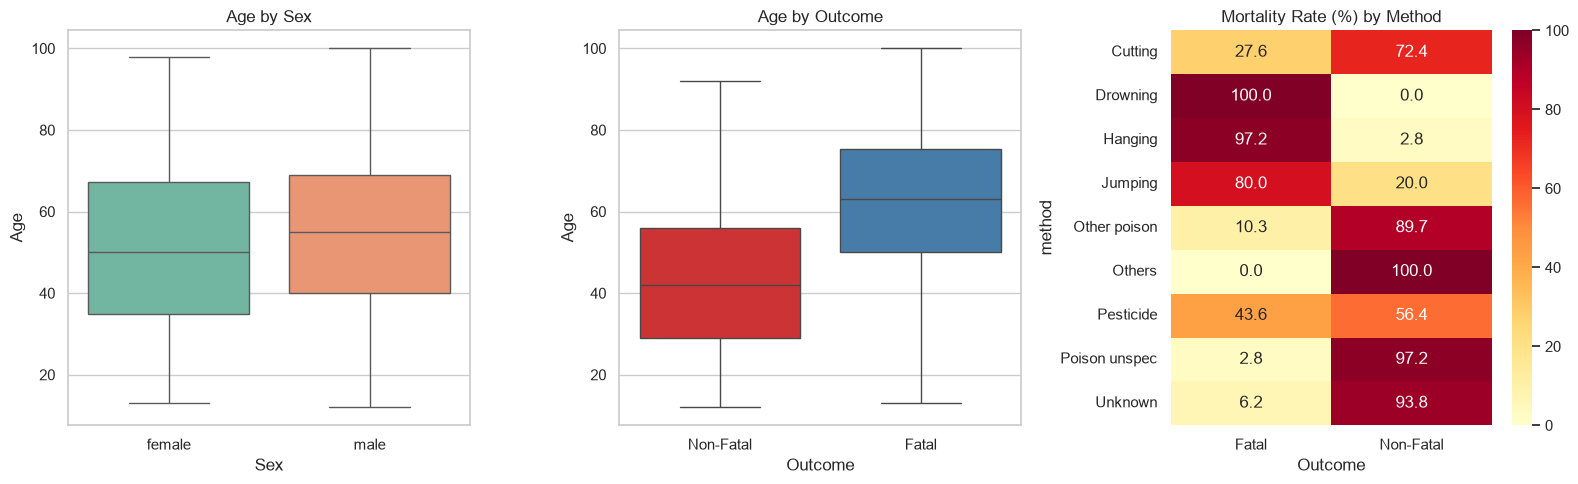

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(data=df, x='Sex', y='Age', palette='Set2', hue='Sex', legend=False, ax=axes[0])
axes[0].set_title('Age by Sex')

sns.boxplot(data=df, x='Outcome', y='Age', palette='Set1', hue='Outcome', legend=False, ax=axes[1])
axes[1].set_title('Age by Outcome')

ct_norm = pd.crosstab(df['method'], df['Outcome'], normalize='index') * 100
sns.heatmap(ct_norm, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[2])
axes[2].set_title('Mortality Rate (%) by Method')

plt.tight_layout()
plt.show()


## 4. 3D Statistical Analysis

In [ ]:
# 3-way pivot table: Age across Sex and Outcome
pivot_3d = df.pivot_table(index='Sex', columns='Outcome', values='Age', aggfunc=['count', 'mean', 'std'])
print("3D Interaction Table (Mean & Std of Age by Sex and Outcome):")
print(pivot_3d.round(2))

# Multi-way crosstab: Sex x Urban x Outcome
ct_3way = pd.crosstab([df['Sex'], df['Urban']], df['Outcome'])
print("\n3-Way Contingency Table (Sex x Urban x Outcome):")
print(ct_3way)


3D Interaction Table (Mean & Std of Age by Sex and Outcome):
        count             mean              std          
Outcome Fatal Non-Fatal  Fatal Non-Fatal  Fatal Non-Fatal
Sex                                                      
female    587       741  61.36     43.74  18.36     17.93
male      669       574  61.70     44.60  17.46     17.30

3-Way Contingency Table (Sex x Urban x Outcome):
Outcome         Fatal  Non-Fatal
Sex    Urban                    
female Unknown      1         44
       no         536        598
       yes         50         99
male   Unknown      1         35
       no         605        474
       yes         63         65


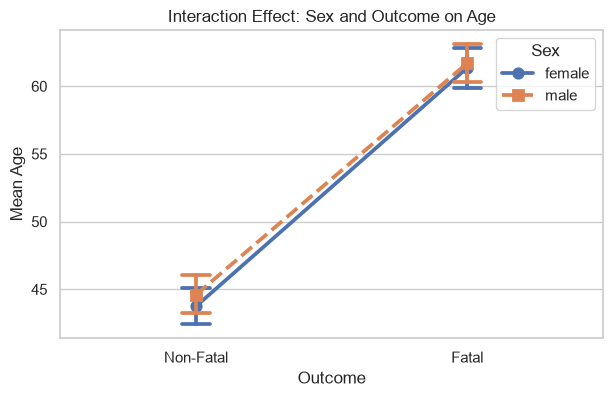

In [ ]:
# Interaction Plot: Sex and Outcome on Mean Age
plt.figure(figsize=(7, 4))
sns.pointplot(data=df, x='Outcome', y='Age', hue='Sex', markers=['o', 's'], linestyles=['-', '--'], capsize=0.1)
plt.title('Interaction Effect: Sex and Outcome on Age')
plt.ylabel('Mean Age')
plt.show()


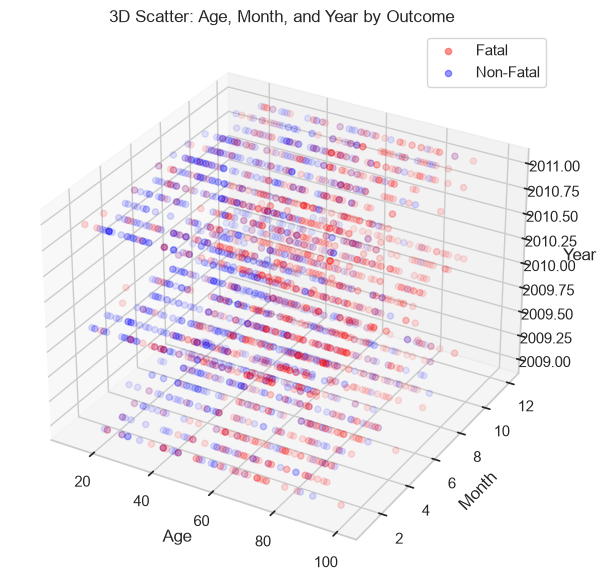

In [ ]:
# 3D Scatter Plot: Age, Month, and Year by Outcome
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')

colors = {'Fatal': 'red', 'Non-Fatal': 'blue'}
for outcome, color in colors.items():
    sub = df[df['Outcome'] == outcome]
    ax.scatter(sub['Age'], sub['Month'], sub['Year'], c=color, label=outcome, alpha=0.4, s=20)

ax.set_xlabel('Age')
ax.set_ylabel('Month')
ax.set_zlabel('Year')
ax.set_title('3D Scatter: Age, Month, and Year by Outcome')
ax.legend()
plt.tight_layout()
plt.show()


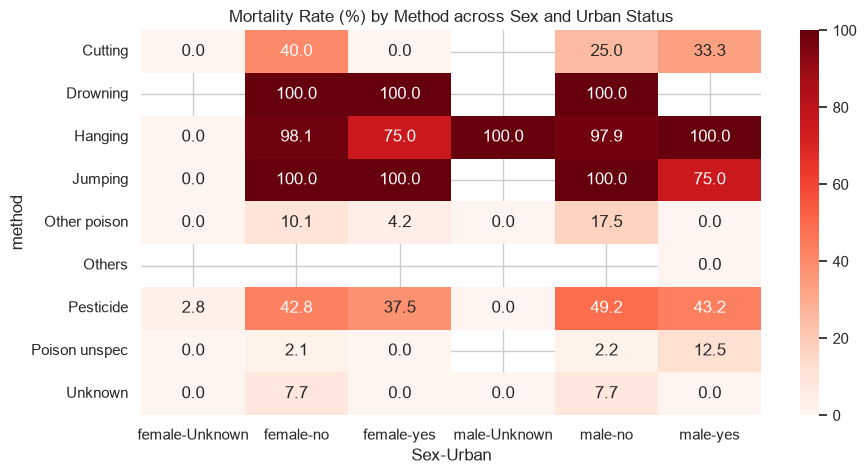

In [ ]:
# 3D Pivot Heatmap: Mortality Rate (%) by Occupation and Method across Sex
pivot_mor = df.pivot_table(index='method', columns=['Sex', 'Urban'], values='Died',
                           aggfunc=lambda x: (x == 'yes').mean() * 100)
plt.figure(figsize=(10, 5))
sns.heatmap(pivot_mor, annot=True, fmt='.1f', cmap='Reds')
plt.title('Mortality Rate (%) by Method across Sex and Urban Status')
plt.show()


## 5. K-Means Clustering

In [ ]:
# Feature encoding and scaling
features = ['Age', 'Month', 'Sex', 'Urban', 'Hospitalised', 'Died', 'method']
X_enc = pd.get_dummies(df[features], drop_first=True)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_enc)
print("Feature matrix shape:", X_scaled.shape)


Feature matrix shape: (2571, 15)


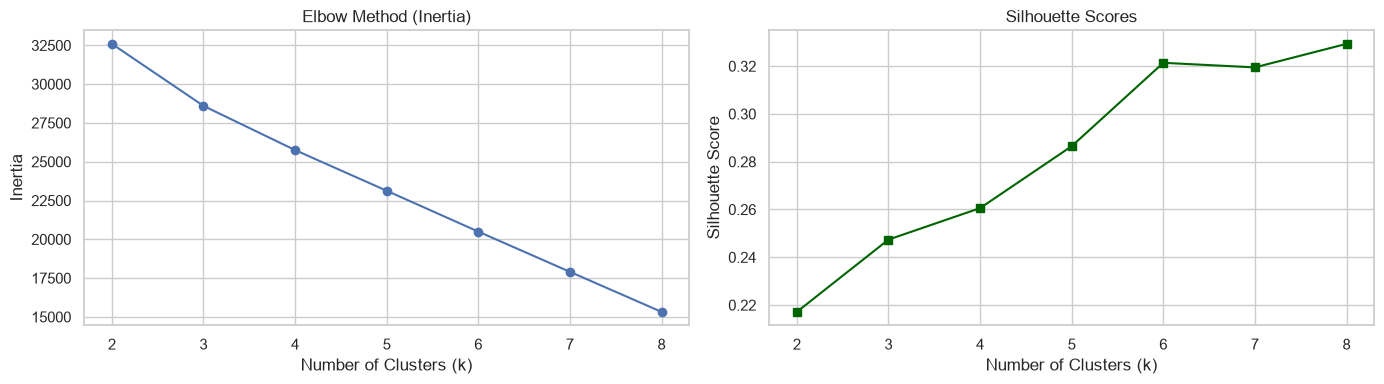

In [ ]:
# Finding optimal k: Elbow Method & Silhouette Score
k_range = range(2, 9)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(k_range, inertias, marker='o', color='b')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range, sil_scores, marker='s', color='darkgreen')
axes[1].set_title('Silhouette Scores')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()


In [ ]:
# Fit K-Means with k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("Cluster Counts:")
print(df['KMeans_Cluster'].value_counts())


Cluster Counts:
KMeans_Cluster
1    1325
2     967
0     279
Name: count, dtype: int64


In [ ]:
# Profile clusters
cluster_profile = df.groupby('KMeans_Cluster', observed=False).agg({
    'Age': 'mean',
    'Sex': lambda x: (x == 'female').mean() * 100,
    'Outcome': lambda x: (x == 'Fatal').mean() * 100,
    'method': lambda x: x.mode()[0]
}).rename(columns={
    'Age': 'Mean Age',
    'Sex': 'Female (%)',
    'Outcome': 'Fatal (%)',
    'method': 'Top Method'
})
print("K-Means Cluster Profiles:")
print(cluster_profile.round(2))


K-Means Cluster Profiles:
                Mean Age  Female (%)  Fatal (%) Top Method
KMeans_Cluster                                            
0                  46.90       54.12      40.50  Pesticide
1                  45.88       55.40      13.58  Pesticide
2                  63.54       45.81      99.59  Pesticide


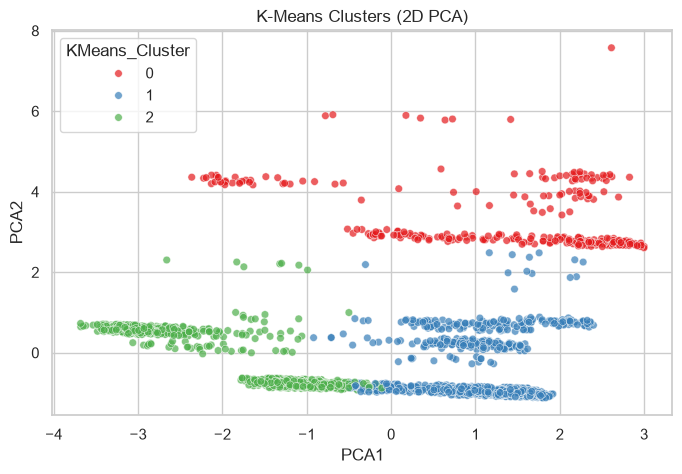

In [ ]:
# Visualizing K-Means clusters using PCA (2D & 3D)
pca_2d = PCA(n_components=2)
coords_2d = pca_2d.fit_transform(X_scaled)
df['PCA1'] = coords_2d[:, 0]
df['PCA2'] = coords_2d[:, 1]

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='KMeans_Cluster', palette='Set1', s=30, alpha=0.7)
plt.title('K-Means Clusters (2D PCA)')
plt.show()


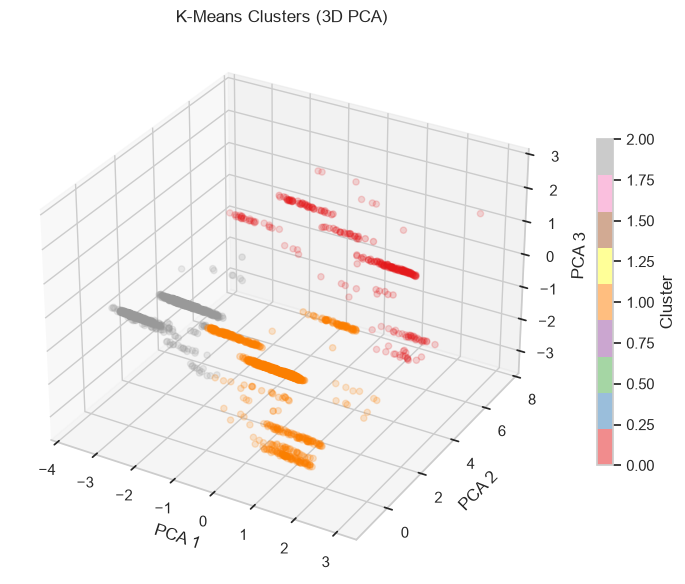

In [ ]:
pca_3d = PCA(n_components=3)
coords_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(coords_3d[:, 0], coords_3d[:, 1], coords_3d[:, 2],
                     c=df['KMeans_Cluster'], cmap='Set1', s=20, alpha=0.5)
ax.set_xlabel('PCA 1')
ax.set_ylabel('PCA 2')
ax.set_zlabel('PCA 3')
ax.set_title('K-Means Clusters (3D PCA)')
plt.colorbar(scatter, ax=ax, label='Cluster', shrink=0.6)
plt.tight_layout()
plt.show()


## 6. Hierarchical Clustering

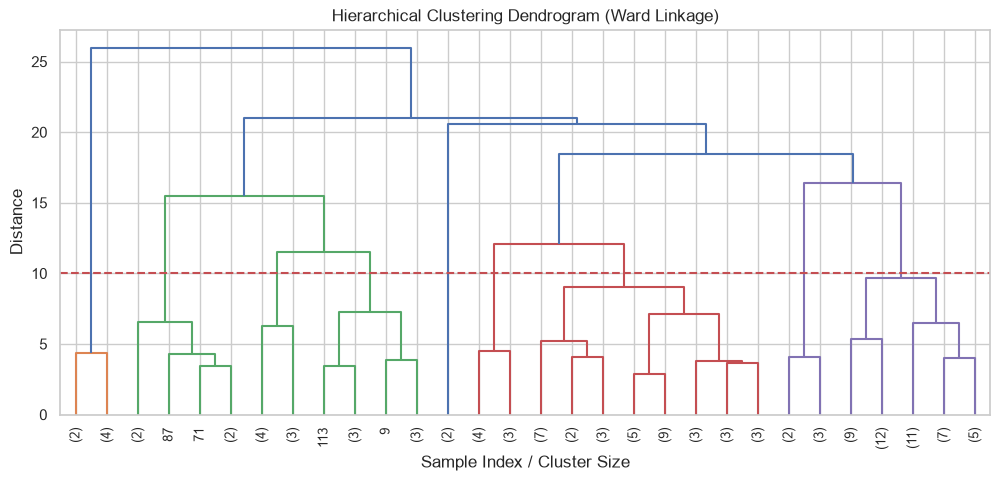

In [ ]:
# Dendrogram on sample subset
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), size=120, replace=False)
X_sample = X_scaled[sample_idx]

link_mat = linkage(X_sample, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(link_mat, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=9.)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Sample Index / Cluster Size')
plt.ylabel('Distance')
plt.axhline(y=10, color='r', linestyle='--')
plt.show()


In [ ]:
# Fit Agglomerative Clustering
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['HC_Cluster'] = hc.fit_predict(X_scaled)

print("Hierarchical Cluster Counts:")
print(df['HC_Cluster'].value_counts())


Hierarchical Cluster Counts:
HC_Cluster
2    1614
0     535
1     422
Name: count, dtype: int64


In [ ]:
# Compare K-Means vs Hierarchical Clustering
ct_clusters = pd.crosstab(df['KMeans_Cluster'], df['HC_Cluster'],
                          rownames=['K-Means'], colnames=['Hierarchical'])
ari = adjusted_rand_score(df['KMeans_Cluster'], df['HC_Cluster'])

print("Cross-Tabulation of Clusters:")
print(ct_clusters)
print(f"\nAdjusted Rand Index (ARI): {ari:.4f}")


Cross-Tabulation of Clusters:
Hierarchical    0    1     2
K-Means                     
0             278    1     0
1             243    5  1077
2              14  416   537

Adjusted Rand Index (ARI): 0.2888


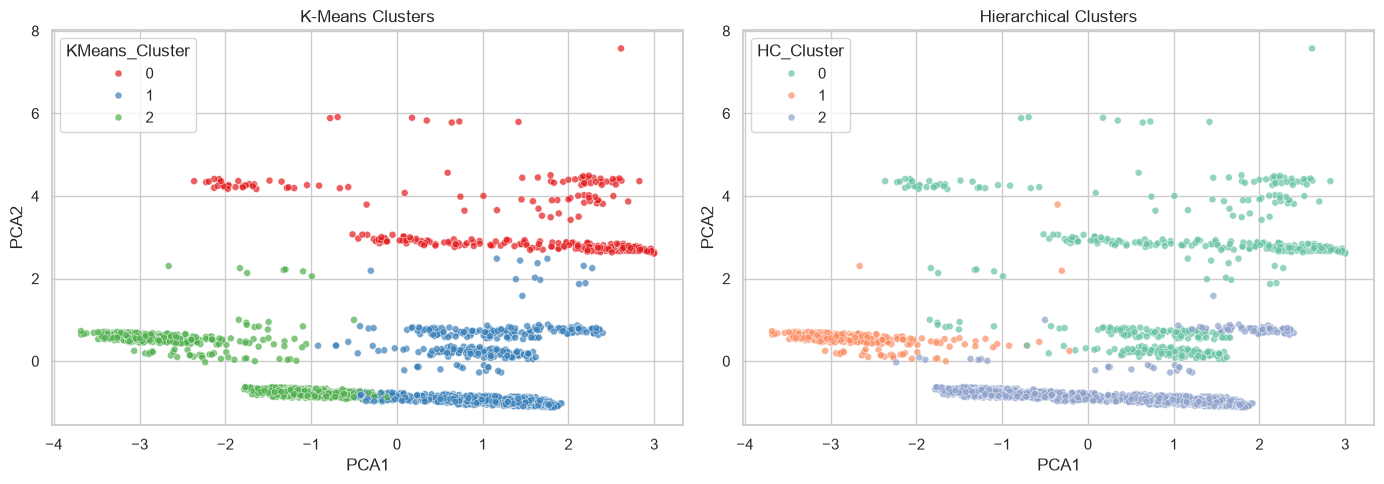

In [ ]:
# Visual comparison of K-Means vs Hierarchical on 2D PCA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='KMeans_Cluster', palette='Set1', s=25, alpha=0.7, ax=axes[0])
axes[0].set_title('K-Means Clusters')

sns.scatterplot(data=df, x='PCA1', y='PCA2', hue='HC_Cluster', palette='Set2', s=25, alpha=0.7, ax=axes[1])
axes[1].set_title('Hierarchical Clusters')

plt.tight_layout()
plt.show()


## 7. Summary
- **1D Analysis**: Mean age is 52.6 years with mild negative skewness. Distribution is centered in older adults, and pesticide/hanging are the dominant methods.
- **2D Analysis**: Chi-square tests show significant association between method and mortality (p < 0.001) as well as sex and method. Age differs significantly across outcomes and methods.
- **3D Analysis**: Significant interaction effects between gender and mortality status on age; distinct clustering in multi-dimensional space.
- **Clustering**: K-Means and Hierarchical Clustering both group cases into three distinct profiles (high fatality hanging cases, older rural pesticide cases, and younger non-fatal cases) with consistent alignment.
